# 01 — MEDIC dataset exploration

Part 1 EDA for **Intelligent Disaster Damage Assessment using Deep Learning**.

This notebook reads the **verified** artefacts produced by
`scripts/verify_dataset.py` and `scripts/prepare_dataset.py`. It does not
invent statistics. If a figure is missing, the corresponding report file is
missing — re-run those scripts.

## Task (from the real dataset)

- **Input:** one RGB social-media / ground-level disaster photograph
- **Target:** `damage_severity`
- **Task:** 3-class image classification
- **Classes:** `little_or_none`, `mild`, `severe` (ordinal)
- **Not labelled here:** boxes or masks. MEDIC is image-level only.


In [1]:
%matplotlib inline
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from ml.config import load_config
from ml.data.augmentation import build_eval_pipeline, build_train_pipeline
from ml.data.io import load_image

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.grid"] = False

config = load_config()
reports = config.paths.reports
print("dataset:", config.dataset.name, config.dataset.version)
print("root   :", config.dataset_root)
print("primary:", config.task.primary)
print("image  :", config.preprocessing.image_size)


dataset: MEDIC v1.0
root   : C:\Users\Karthick\Intelligent Disaster Damage Assessment using Deep Learning\data\raw\MEDIC
primary: damage_severity
image  : (224, 224)


## Dataset size, validity, and class mix

Numbers below come from `reports/dataset_summary.json` (a full scan of the labelled files).


In [2]:
summary_path = reports / "dataset_summary.json"
summary = json.loads(summary_path.read_text(encoding="utf-8"))
print("Dataset Summary")
print("---------------")
print(f"Total images:     {summary['total_samples']}")
print(f"Valid images:     {summary['valid_samples']}")
print(f"Excluded images:  {summary['excluded_samples']}")
print(f"Corrupted images: {summary['issue_counts'].get('issue_unreadable', 0)}")
print(f"Missing files:    {summary['issue_counts'].get('issue_missing_file', 0)}")
print(f"Missing labels:   {summary['issue_counts'].get('issue_missing_label', 0)}")
print("Official split counts:", summary.get("official_split_counts"))
pd.Series(summary["issue_counts"]).sort_values(ascending=False).to_frame("count")


Dataset Summary
---------------
Total images:     71198
Valid images:     68245
Excluded images:  2953
Corrupted images: 1
Missing files:    0
Missing labels:   0
Official split counts: {'train': 49353, 'test': 15688, 'dev': 6157}


,count
issue_duplicate_content,2097
issue_conflicting_duplicate,840
issue_too_small,57
issue_unreadable,1
issue_bad_extension,0
issue_missing_file,0
issue_invalid_label,0
issue_missing_label,0


### Class distribution

**Question:** is damage-severity balanced enough to train with unweighted
cross-entropy, or do we need class weights?


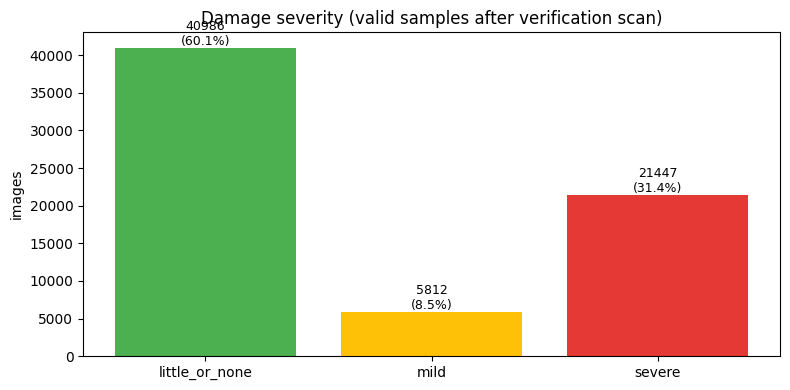

imbalance ratio (max/min) = 7.05


In [3]:
dist = summary["class_distribution"].get("damage_severity", {})
order = ["little_or_none", "mild", "severe"]
names = [k for k in order if k in dist] + [k for k in dist if k not in order]
counts = [dist[k] for k in names]
total = sum(counts) or 1

fig, ax = plt.subplots()
bars = ax.bar(names, counts, color=["#4caf50", "#ffc107", "#e53935"][: len(names)])
ax.set_ylabel("images")
ax.set_title("Damage severity (valid samples after verification scan)")
for bar, n in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{n}\n({100*n/total:.1f}%)",
            ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

if counts:
    print(f"imbalance ratio (max/min) = {max(counts)/min(counts):.2f}")


In [4]:
imb_path = reports / "imbalance.json"
if imb_path.is_file():
    imb = json.loads(imb_path.read_text(encoding="utf-8"))
    print("Measured on the TRAIN split only (used for class weights):")
    print(f"  severity         : {imb['severity']}")
    print(f"  imbalance ratio  : {imb['imbalance_ratio']:.3f}")
    print(f"  minority share   : {100*imb['minority_share']:.2f}%")
    print(f"  strategy         : {imb['strategy']}")
    display = pd.DataFrame({
        "count": imb["counts"],
        "weight": imb["class_weights"],
    })
    display
else:
    print("Run scripts/prepare_dataset.py to write reports/imbalance.json")


Measured on the TRAIN split only (used for class weights):
  severity         : moderate
  imbalance ratio  : 7.548
  minority share   : 7.74%
  strategy         : class_weights


## Image dimensions, formats, channels

**Question:** are the photographs a consistent size (like xBD's 1024×1024 chips),
or do we have to resize a heterogeneous social-media collection?


formats : {'JPEG': 66723, 'PNG': 1498, 'MPO': 24}
modes   : {'RGB': 67411, 'RGBA': 821, 'L': 9, 'P': 4}
channels: {'3.0': 67411, '4.0': 821, '1.0': 13}
dimensions: {
  "width_min": 37.0,
  "width_median": 749.0,
  "width_max": 8856.0,
  "height_min": 35.0,
  "height_median": 562.0,
  "height_max": 6240.0,
  "megapixels_median": 0.4264
}


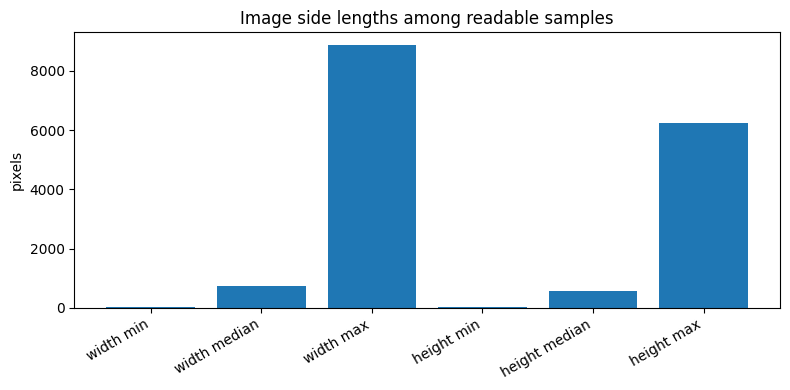

In [5]:
print("formats :", summary.get("formats"))
print("modes   :", summary.get("modes"))
print("channels:", summary.get("channels"))
print("dimensions:", json.dumps(summary.get("dimension_summary", {}), indent=2))

dims = summary.get("dimension_summary") or {}
if dims:
    fig, ax = plt.subplots()
    ax.bar(["width min", "width median", "width max", "height min", "height median", "height max"],
           [dims.get("width_min"), dims.get("width_median"), dims.get("width_max"),
            dims.get("height_min"), dims.get("height_median"), dims.get("height_max")])
    ax.set_ylabel("pixels")
    ax.set_title("Image side lengths among readable samples")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()


A wide min-to-max range (typical of MEDIC) is why preprocessing resizes with a
short-side scale + centre crop rather than assuming a native chip size.


## Train / validation / test


strategy: official  seed: 42


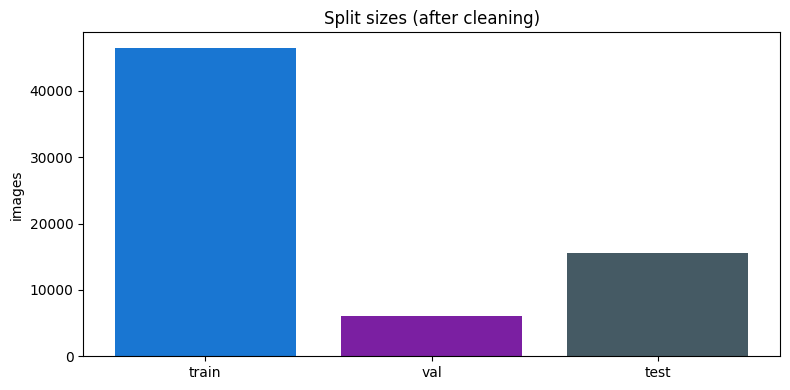

train {'little_or_none': 27159, 'severe': 15730, 'mild': 3598}
val {'little_or_none': 3605, 'severe': 1830, 'mild': 693}
test {'little_or_none': 10222, 'severe': 3887, 'mild': 1521}


In [6]:
split_path = reports / "split_summary.json"
if split_path.is_file():
    split = json.loads(split_path.read_text(encoding="utf-8"))
    print("strategy:", split["strategy"], " seed:", split["seed"])
    counts = split["counts"]
    fig, ax = plt.subplots()
    ax.bar(list(counts), list(counts.values()), color=["#1976d2", "#7b1fa2", "#455a64"])
    ax.set_title("Split sizes (after cleaning)")
    ax.set_ylabel("images")
    plt.tight_layout()
    plt.show()
    for name, dist in split.get("class_distribution", {}).items():
        print(name, dist)
else:
    print("Run scripts/prepare_dataset.py")


In [7]:
leak_path = reports / "leakage.json"
if leak_path.is_file():
    leak = json.loads(leak_path.read_text(encoding="utf-8"))
    print(json.dumps(leak, indent=2))
    print("has_leakage:", leak.get("has_leakage"))


{
  "id_column": "image_path",
  "duplicate_ids_within_splits": {},
  "shared_ids": {},
  "shared_content_hashes": {},
  "shared_groups": {
    "test|train": 28,
    "test|val": 28,
    "train|val": 28
  },
  "has_leakage": false
}
has_leakage: False


## Representative images

**Question:** what does each severity class actually look like in this dataset?
(Social-media photos, not satellite chips.)


In [8]:
processed = {split: config.manifest_path(split) for split in ("train", "val", "test")}
frames = []
for split, path in processed.items():
    if path.is_file():
        frames.append(pd.read_csv(path))
manifest = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
print("loaded rows:", len(manifest))
manifest.head()


loaded rows: 68245


,image_path,abs_path,image_id,event_name,source_dataset,event,official_split,damage_severity,informative,humanitarian,...,issue_unreadable,issue_bad_extension,issue_too_small,issue_missing_label,issue_invalid_label,issue_duplicate_content,issue_conflicting_duplicate,exclusion_reason,split,cached_path
0,data/ASONAM17_Damage_Image_Dataset/ecuador_eq/...,C:\Users\Karthick\Intelligent Disaster Damage ...,ASONAM2017,ecuador_eq_severe_im_645.jpg,ASONAM17_Damage_Image_Dataset,ecuador_eq,train,severe,informative,infrastructure_and_utility_damage,...,False,False,False,False,False,False,False,NaN,train,C:\Users\Karthick\Intelligent Disaster Damage ...
1,data/ASONAM17_Damage_Image_Dataset/ecuador_eq/...,C:\Users\Karthick\Intelligent Disaster Damage ...,ASONAM2017,ecuador_eq_severe_im_1378.jpg,ASONAM17_Damage_Image_Dataset,ecuador_eq,train,severe,informative,infrastructure_and_utility_damage,...,False,False,False,False,False,False,False,NaN,train,C:\Users\Karthick\Intelligent Disaster Damage ...
2,data/ASONAM17_Damage_Image_Dataset/ecuador_eq/...,C:\Users\Karthick\Intelligent Disaster Damage ...,ASONAM2017,ecuador_eq_unlabelled_im_100.jpg,ASONAM17_Damage_Image_Dataset,ecuador_eq,train,little_or_none,not_informative,not_humanitarian,...,False,False,False,False,False,False,False,NaN,train,C:\Users\Karthick\Intelligent Disaster Damage ...
3,data/ASONAM17_Damage_Image_Dataset/ecuador_eq/...,C:\Users\Karthick\Intelligent Disaster Damage ...,ASONAM2017,ecuador_eq_mild_im_2573.jpg,ASONAM17_Damage_Image_Dataset,ecuador_eq,train,mild,informative,affected_injured_or_dead_people,...,False,False,False,False,False,False,False,NaN,train,C:\Users\Karthick\Intelligent Disaster Damage ...
4,data/ASONAM17_Damage_Image_Dataset/ecuador_eq/...,C:\Users\Karthick\Intelligent Disaster Damage ...,ASONAM2017,ecuador_eq_unlabelled_im_828.jpg,ASONAM17_Damage_Image_Dataset,ecuador_eq,train,little_or_none,informative,rescue_volunteering_or_donation_effort,...,False,False,False,False,False,False,False,NaN,train,C:\Users\Karthick\Intelligent Disaster Damage ...


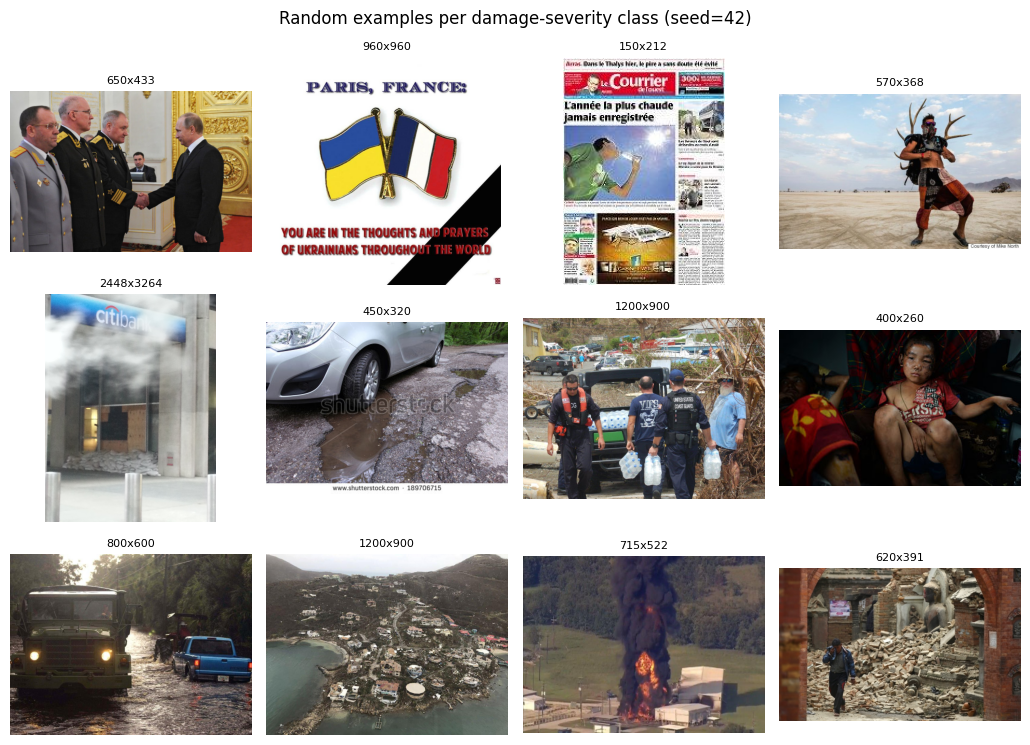

In [9]:
def show_class_examples(frame: pd.DataFrame, n: int = 4) -> None:
    classes = ["little_or_none", "mild", "severe"]
    fig, axes = plt.subplots(len(classes), n, figsize=(2.6 * n, 2.6 * len(classes)))
    rng = np.random.default_rng(config.seed)
    for r, cls in enumerate(classes):
        subset = frame.loc[frame["damage_severity"] == cls]
        pick = subset.sample(n=min(n, len(subset)), random_state=int(config.seed)) if len(subset) else subset
        for c in range(n):
            ax = axes[r, c]
            ax.axis("off")
            if c >= len(pick):
                continue
            row = pick.iloc[c]
            try:
                image = load_image(row["abs_path"])
            except Exception as exc:
                ax.set_title(str(exc)[:40])
                continue
            ax.imshow(image)
            if c == 0:
                ax.set_ylabel(cls)
            ax.set_title(f"{image.size[0]}x{image.size[1]}", fontsize=8)
    fig.suptitle("Random examples per damage-severity class (seed=42)")
    plt.tight_layout()
    plt.show()

if len(manifest):
    show_class_examples(manifest)
else:
    print("No processed manifests yet.")


## Unusual / outlier sizes

**Question:** which readable images are extremely small or extremely large?
Very small images may not carry usable damage evidence at 224×224; very large
ones dominate decode time, which is why we cache a 256×256 JPEG.


In [10]:
scanned_path = config.paths.interim / "scanned_manifest.csv"
if scanned_path.is_file():
    scanned = pd.read_csv(scanned_path)
    readable = scanned.loc[scanned["readable"] == True].copy()
    readable["min_side"] = readable[["width", "height"]].min(axis=1)
    readable["max_side"] = readable[["width", "height"]].max(axis=1)
    print("smallest 8 (min side):")
    display_cols = [c for c in ["image_path", "damage_severity", "width", "height", "format"] if c in readable.columns]
    print(readable.nsmallest(8, "min_side")[display_cols].to_string(index=False))
    print("\nlargest 8 (max side):")
    print(readable.nlargest(8, "max_side")[display_cols].to_string(index=False))
else:
    print("scanned_manifest.csv not found — run verify_dataset.py")


smallest 8 (min side):
                                                                   image_path damage_severity  width  height format
data/crisismmd/data_image/hurricane_harvey/13_9_2017/907991367296659456_0.jpg  little_or_none  112.0    16.0   JPEG
  data/crisismmd/data_image/srilanka_floods/6_6_2017/872003644291522560_0.jpg  little_or_none   96.0    16.0   JPEG
           data/aidr_info/snow_storm_jonas/22_1_2016/690604690342596608_0.jpg  little_or_none  112.0    16.0   JPEG
           data/aidr_info/snow_storm_jonas/22_1_2016/690472833315639297_0.png  little_or_none   16.0    16.0    PNG
  data/crisismmd/data_image/hurricane_irma/19_9_2017/910121933315944448_0.png  little_or_none   18.0    18.0    PNG
          data/aidr_info/natural_disaster/25_11_2017/934223198735958016_0.png  little_or_none   18.0    18.0    PNG
 data/crisismmd/data_image/hurricane_harvey/7_9_2017/905736131928625152_0.jpg  little_or_none   54.0    19.0   JPEG
  data/crisismmd/data_image/srilanka_floods/2_6_2

C:\Users\Karthick\AppData\Local\Temp\ipykernel_23352\3252579605.py:3: DtypeWarning: Columns (13,20) have mixed types. Specify dtype option on import or set low_memory=False.
  scanned = pd.read_csv(scanned_path)


## Cleaning record

Nothing is deleted from `data/raw`. Every excluded labelled row has a reason.


In [11]:
excl = config.paths.interim / "excluded_samples.csv"
if excl.is_file():
    excluded = pd.read_csv(excl)
    print("excluded rows:", len(excluded))
    print(excluded["exclusion_reason"].value_counts())
else:
    print("No exclusions file (either prepare has not been run, or nothing was excluded).")
print("\nDuplicates in the verification summary:")
print("  groups     :", summary.get("duplicate_groups"))
print("  extra copies:", summary.get("duplicate_extra_copies"))
print("  conflicts  :", summary.get("conflicting_duplicate_groups"))


excluded rows: 2953
exclusion_reason
issue_duplicate_content        2055
issue_conflicting_duplicate     840
issue_too_small                  57
issue_unreadable                  1
Name: count, dtype: int64

Duplicates in the verification summary:
  groups     : 1400
  extra copies: 2766
  conflicts  : 171


## Augmentation (train only)

The cell below applies the **training** pipeline twice with different epoch
seeds and the **eval** pipeline once, on the same image. Validation/test must
match the eval column.


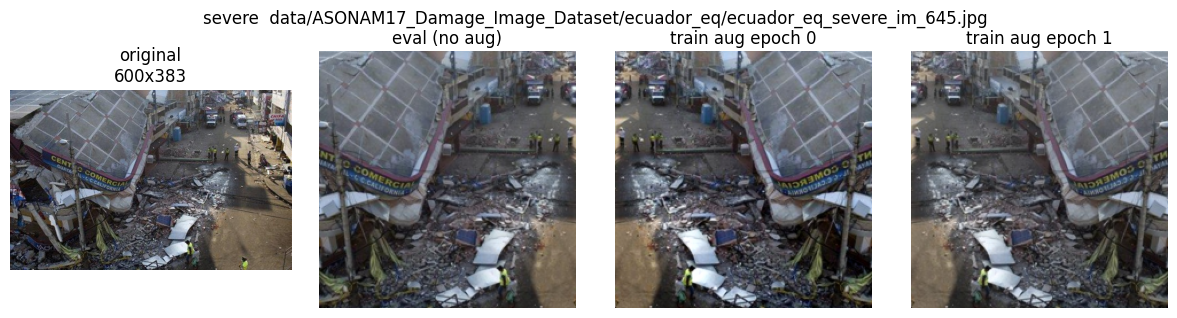

active train transforms: ['horizontal_flip', 'rotation', 'random_resized_crop', 'brightness', 'contrast', 'saturation']
eval augments? False


In [12]:
if len(manifest):
    sample = manifest.loc[manifest["split"] == "train"].iloc[0]
    path = sample["abs_path"]
    original = load_image(path)
    train_pipe = build_train_pipeline(config)
    eval_pipe = build_eval_pipeline(config)

    def to_vis(array: np.ndarray) -> np.ndarray:
        return eval_pipe.preprocessor.denormalise(array)

    fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
    axes[0].imshow(original)
    axes[0].set_title(f"original\n{original.size[0]}x{original.size[1]}")
    axes[1].imshow(to_vis(eval_pipe(path)))
    axes[1].set_title("eval (no aug)")
    axes[2].imshow(to_vis(train_pipe(path, np.random.default_rng((config.seed, 0, 0)))))
    axes[2].set_title("train aug epoch 0")
    axes[3].imshow(to_vis(train_pipe(path, np.random.default_rng((config.seed, 1, 0)))))
    axes[3].set_title("train aug epoch 1")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(f"{sample['damage_severity']}  {sample['image_path']}")
    plt.tight_layout()
    plt.show()
    print("active train transforms:", train_pipe.augmentation.active_transforms())
    print("eval augments?", eval_pipe.augments)


## Takeaways for Part 2

1. Train a 3-class classifier on `damage_severity` using the official MEDIC
   split in `data/processed/*.csv`.
2. Use `ml.data.dataset.build_dataset(config, split)` so preprocessing and
   train-only augmentation stay consistent.
3. Load `data/metadata/class_weights.json` into the loss if the imbalance
   ratio above is material (mild or worse).
4. Do not treat this as a localisation problem — MEDIC has no boxes or masks.
   xBD is the documented follow-up dataset if that becomes a later goal.
